# Week 2 — Prompt Engineering for Green-Claim Extraction

## 1. Objective
This notebook evaluates how prompt design affects the accuracy, consistency and format reliability of an open-weight language model. One baseline prompt and two engineered prompts are run on the same fixed test set, and their outputs are scored against a hand-written answer key.

## 2. Task Definition
**Task:** given a product listing, extract its environmental claims into structured JSON and classify how well those claims are substantiated.

Retailers and regulators increasingly expect environmental claims to be specific and verifiable. Vague phrases such as "eco-friendly" or "kind to the planet" are a common form of greenwashing. An automated first-pass screen helps a marketplace review thousands of listings, but only if its output is accurate and machine-readable, which makes this a strict test of prompt design. The task combines two of the lab's workplace tasks, **extracting** and **classifying**, and links to **SDG 12, target 12.8** (people have the relevant information for sustainable lifestyles).

| Field | Type | Scored for accuracy |
|---|---|---|
| `product_name` | string | Yes |
| `recycled_content_percent` | number or null | Yes |
| `certifications` | list of strings | Yes |
| `vague_claims` | list of quoted phrases | No (used for the hallucination check) |
| `has_vague_claim` | true / false | Yes |
| `overall_rating` | SUBSTANTIATED / PARTLY_SUBSTANTIATED / UNSUBSTANTIATED / NO_CLAIMS | Yes |

**Model:** `Qwen/Qwen2.5-3B-Instruct` (Qwen Research License: research and evaluation use only), the same model used in Week 1, so findings carry across tasks. Week 1 showed this model adding the vague term "eco-friendly" to product copy on its own, which motivates testing whether it can detect such terms reliably.

## 3. Test Inputs and Answer Key
Eight short product listings were written for this task so that the correct answer for every field is known exactly. The answer key was fixed before any model was run. Each listing tests a specific difficulty:

| ID | Product | What it tests | Expected rating |
|---|---|---|---|
| 1 | TerraFlask | All claims measurable; reuses the Week 1 brief | SUBSTANTIATED |
| 2 | GreenWave Tote | Only vague claims | UNSUBSTANTIATED |
| 3 | Solace T-Shirt | A certification alongside a vague superlative | PARTLY_SUBSTANTIATED |
| 4 | UrbanBrew Grinder | No environmental claims; "cardboard box" is a distractor | NO_CLAIMS |
| 5 | EverLeaf Notebook | Recycled percentage plus a certification | SUBSTANTIATED |
| 6 | AquaPure Shampoo Bar | "100% natural" is not recycled content (number trap); a standard plus vague claims | PARTLY_SUBSTANTIATED |
| 7 | Nordic Trail Jacket | Two recycled percentages; a certification written with a ® symbol | SUBSTANTIATED |
| 8 | SunCharge Power Bank | Green-sounding feature language with nothing measurable | UNSUBSTANTIATED |

## 4. Environment Setup

In [1]:
import json, os, re, time, platform
import torch, transformers
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

os.makedirs("outputs", exist_ok=True)
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="cuda")
print("Model loaded:", MODEL_ID)

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | transformers: 5.22.1
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-3B-Instruct


### 4.1 Test set, answer key and scoring functions

In [2]:
import json, re

TEST_SET = [
    {"id": 1,
     "listing": "Product: TerraFlask\nDescription: A reusable insulated water bottle made from 90% recycled stainless steel with a bamboo lid. Keeps drinks cold for 24 hours and replaces up to 150 single-use plastic bottles a year.",
     "key": {"product_name": "TerraFlask", "recycled_content_percent": 90, "certifications": [],
             "has_vague_claim": False, "overall_rating": "SUBSTANTIATED"}},
    {"id": 2,
     "listing": "Product: GreenWave Tote\nDescription: An eco-friendly, planet-loving shopping bag for conscious shoppers. Naturally better for the earth.",
     "key": {"product_name": "GreenWave Tote", "recycled_content_percent": None, "certifications": [],
             "has_vague_claim": True, "overall_rating": "UNSUBSTANTIATED"}},
    {"id": 3,
     "listing": "Product: Solace Organic Cotton T-Shirt\nDescription: Made from GOTS-certified organic cotton and coloured with low-impact dyes. Our most sustainable tee yet.",
     "key": {"product_name": "Solace Organic Cotton T-Shirt", "recycled_content_percent": None, "certifications": ["GOTS"],
             "has_vague_claim": True, "overall_rating": "PARTLY_SUBSTANTIATED"}},
    {"id": 4,
     "listing": "Product: UrbanBrew Coffee Grinder\nDescription: Stainless steel conical burrs, 12 grind settings and a 2-year warranty. Ships in a cardboard box.",
     "key": {"product_name": "UrbanBrew Coffee Grinder", "recycled_content_percent": None, "certifications": [],
             "has_vague_claim": False, "overall_rating": "NO_CLAIMS"}},
    {"id": 5,
     "listing": "Product: EverLeaf Notebook\nDescription: 100% recycled paper, FSC-certified, printed with soy-based inks. 120 lined pages.",
     "key": {"product_name": "EverLeaf Notebook", "recycled_content_percent": 100, "certifications": ["FSC"],
             "has_vague_claim": False, "overall_rating": "SUBSTANTIATED"}},
    {"id": 6,
     "listing": "Product: AquaPure Shampoo Bar\nDescription: Zero waste and kind to the planet, with 100% natural ingredients. Wrapped in compostable paper certified to EN 13432.",
     "key": {"product_name": "AquaPure Shampoo Bar", "recycled_content_percent": None, "certifications": ["EN 13432"],
             "has_vague_claim": True, "overall_rating": "PARTLY_SUBSTANTIATED"}},
    {"id": 7,
     "listing": "Product: Nordic Trail Jacket\nDescription: The shell fabric contains 60% recycled polyester and the lining is 30% recycled nylon. bluesign® approved fabrics.",
     "key": {"product_name": "Nordic Trail Jacket", "recycled_content_percent": 60, "certifications": ["bluesign"],
             "has_vague_claim": False, "overall_rating": "SUBSTANTIATED"}},
    {"id": 8,
     "listing": "Product: SunCharge Power Bank\nDescription: Charges your phone with clean solar energy. A greener way to stay powered, helping save the planet one charge at a time.",
     "key": {"product_name": "SunCharge Power Bank", "recycled_content_percent": None, "certifications": [],
             "has_vague_claim": True, "overall_rating": "UNSUBSTANTIATED"}},
]

SCORED_FIELDS = ["product_name", "recycled_content_percent", "certifications", "has_vague_claim", "overall_rating"]
REQUIRED_TYPES = {
    "product_name": str,
    "recycled_content_percent": (int, float, type(None)),
    "certifications": list,
    "vague_claims": list,
    "has_vague_claim": bool,
    "overall_rating": str,
}
RATINGS = {"SUBSTANTIATED", "PARTLY_SUBSTANTIATED", "UNSUBSTANTIATED", "NO_CLAIMS"}


def norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def parse_output(text):
    """Return (parsed_dict_or_None, is_format_compliant)."""
    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    try:
        obj = json.loads(cleaned)
    except json.JSONDecodeError:
        return None, False
    if not isinstance(obj, dict):
        return None, False
    compliant = (
        set(obj) == set(REQUIRED_TYPES)
        and all(isinstance(obj[k], t) for k, t in REQUIRED_TYPES.items())
        and not isinstance(obj["recycled_content_percent"], bool)
        and obj["overall_rating"] in RATINGS
    )
    return obj, compliant


def to_number(value):
    if value is None:
        return None
    try:
        return float(str(value).replace("%", "").strip())
    except ValueError:
        return "invalid"


def field_scores(obj, key):
    """1 = field correct, 0 = wrong. Unparseable output scores 0 on every field."""
    if obj is None:
        return {f: 0 for f in SCORED_FIELDS}
    gold_pct = None if key["recycled_content_percent"] is None else float(key["recycled_content_percent"])
    certs = obj.get("certifications") if isinstance(obj.get("certifications"), list) else []
    pred_certs = {norm(c) for c in certs}
    gold_certs = {norm(c) for c in key["certifications"]}
    rating = str(obj.get("overall_rating", "")).upper().strip().replace(" ", "_")
    return {
        "product_name": int(norm(obj.get("product_name", "")) == norm(key["product_name"])),
        "recycled_content_percent": int(to_number(obj.get("recycled_content_percent")) == gold_pct),
        "certifications": int(len(pred_certs) == len(gold_certs)
                              and all(any(g in p for p in pred_certs) for g in gold_certs)),
        "has_vague_claim": int(obj.get("has_vague_claim") is key["has_vague_claim"]),
        "overall_rating": int(rating == key["overall_rating"]),
    }


def count_hallucinations(obj, listing):
    """Values the model returned that do not appear in the source listing. None if output is not JSON."""
    if obj is None:
        return None
    src = listing.lower()
    count = 0
    pct = to_number(obj.get("recycled_content_percent"))
    if isinstance(pct, float) and f"{pct:g}%" not in src:
        count += 1
    for c in obj.get("certifications") or []:
        if norm(c) not in norm(listing):
            count += 1
    for phrase in obj.get("vague_claims") or []:
        if str(phrase).lower().strip(" .\"'") not in src:
            count += 1
    return count


def comparable(obj, field, run_tag):
    """Value used to check agreement across runs; failed parses never agree with each other."""
    if obj is None:
        return ("PARSE_FAIL", run_tag)
    value = obj.get(field)
    if field == "certifications" and isinstance(value, list):
        return tuple(sorted(norm(v) for v in value))
    if field == "recycled_content_percent":
        return to_number(value)
    return norm(value)

## 5. Prompt Versions
Three prompts are compared. **v1** reproduces the lab's baseline wording. **v2** applies the prompt-engineering techniques from the Week 2 lecture and lab. **v3** is v2 with the worked example removed, an ablation that isolates how much the example contributes.

| Technique | v1 baseline | v2 improved | v3 no example |
|---|---|---|---|
| Role assigned in a system prompt | – | ✓ | ✓ |
| Explicit field list with types | – | ✓ | ✓ |
| Output format constraint (JSON only) | – | ✓ | ✓ |
| Null / empty-list fallback for missing values | – | ✓ | ✓ |
| Closed label set with definitions | – | ✓ | ✓ |
| Grounding instruction ("do not infer") | – | ✓ | ✓ |
| Disambiguation rules (first percentage; non-recycled percentages) | – | ✓ | ✓ |
| One worked example (one-shot) | – | ✓ | – |

In [3]:
PROMPT_V1_USER = "Extract the important information from this product description:\n\n{listing}"

SYSTEM_V2 = (
    "You are a compliance analyst who reviews environmental claims in product listings "
    "for an online marketplace. You extract information exactly as written and never guess."
)

INSTRUCTIONS_V2 = """Extract information from the product listing below and return ONLY a JSON object, with no other text.

Fields:
- "product_name": string, the product name exactly as written.
- "recycled_content_percent": number or null. The recycled-content percentage stated for the product. If several are stated, use the first. Use null if none is stated. Other percentages (for example "100% natural") are not recycled content.
- "certifications": list of strings. Named third-party certifications or standards (for example "GOTS"). Use [] if none.
- "vague_claims": list of strings. Environmental phrases that cannot be measured or verified, copied word for word from the listing. Use [] if none.
- "has_vague_claim": true or false.
- "overall_rating": exactly one of "SUBSTANTIATED", "PARTLY_SUBSTANTIATED", "UNSUBSTANTIATED", "NO_CLAIMS".

Rating rules:
- SUBSTANTIATED: the listing makes environmental claims and all of them are specific or measurable (percentages, quantities, named certifications).
- PARTLY_SUBSTANTIATED: the listing mixes specific and vague environmental claims.
- UNSUBSTANTIATED: every environmental claim is vague.
- NO_CLAIMS: the listing makes no environmental claims.

Do not infer or add information that is not in the listing.
"""

EXAMPLE_V2 = """
Example
Listing:
Product: BrightBeam Desk Lamp
Description: Uses 40% less energy than a standard bulb. Made from responsibly sourced materials. Energy Star certified.
Output:
{"product_name": "BrightBeam Desk Lamp", "recycled_content_percent": null, "certifications": ["Energy Star"], "vague_claims": ["responsibly sourced materials"], "has_vague_claim": true, "overall_rating": "PARTLY_SUBSTANTIATED"}
"""

TASK_V2 = """
Listing:
{listing}
Output:"""

PROMPTS = {
    "v1_baseline": {"system": None, "user": PROMPT_V1_USER},
    "v2_improved": {"system": SYSTEM_V2, "user": INSTRUCTIONS_V2 + EXAMPLE_V2 + TASK_V2},
    "v3_no_example": {"system": SYSTEM_V2, "user": INSTRUCTIONS_V2 + TASK_V2},
}


for name, p in PROMPTS.items():
    print(f"========== {name} ==========")
    print("[system]", p["system"])
    print("[user]", p["user"].replace("{listing}", "<listing inserted here>"), "\n")

========== v1_baseline ==========
[system] None
[user] Extract the important information from this product description:

<listing inserted here> 

========== v2_improved ==========
[system] You are a compliance analyst who reviews environmental claims in product listings for an online marketplace. You extract information exactly as written and never guess.
[user] Extract information from the product listing below and return ONLY a JSON object, with no other text.

Fields:
- "product_name": string, the product name exactly as written.
- "recycled_content_percent": number or null. The recycled-content percentage stated for the product. If several are stated, use the first. Use null if none is stated. Other percentages (for example "100% natural") are not recycled content.
- "certifications": list of strings. Named third-party certifications or standards (for example "GOTS"). Use [] if none.
- "vague_claims": list of strings. Environmental phrases that cannot be measured or verified, copi

## 6. Experimental Design
Each prompt is run on all 8 listings 4 times: three sampled runs (temperature 0.7, top-p 0.9, seeds 1–3) and one greedy run (no sampling). That gives 3 × 8 × 4 = **96 generations**, each limited to 300 new tokens.

**Metrics**
- **Accuracy:** share of the 5 scored fields that match the answer key. An output that cannot be parsed as JSON scores 0 on every field, because a downstream system cannot use it.
- **Consistency:** share of fields that are identical across the three sampled runs of the same input.
- **Valid JSON** and **format compliance:** exactly the six required keys, correct types, and a rating from the allowed set.
- **Hallucinated values:** percentages, certifications or quoted phrases that do not appear in the listing (JSON outputs only).
- **Lab rubric (1–5):** each rate is mapped to the lab's scale as 1 + 4 × rate.

In [4]:
def generate(messages, temperature, seed, max_new_tokens=300):
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt_text, return_tensors="pt").to("cuda")
    torch.manual_seed(seed)
    if temperature > 0:
        settings = dict(do_sample=True, temperature=temperature, top_p=0.9)
    else:
        settings = dict(do_sample=False)
    start = time.time()
    output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, **settings)
    seconds = round(time.time() - start, 2)
    text = tokenizer.decode(output_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return text, seconds

RUNS = [("seed1", 0.7, 1), ("seed2", 0.7, 2), ("seed3", 0.7, 3), ("greedy", 0.0, 0)]


def build_messages(prompt, listing):
    messages = []
    if prompt["system"]:
        messages.append({"role": "system", "content": prompt["system"]})
    messages.append({"role": "user", "content": prompt["user"].replace("{listing}", listing)})
    return messages


def run_experiments(generate_fn):
    rows = []
    total = len(PROMPTS) * len(TEST_SET) * len(RUNS)
    done = 0
    for p_name, prompt in PROMPTS.items():
        for item in TEST_SET:
            for run_tag, temperature, seed in RUNS:
                raw, seconds = generate_fn(build_messages(prompt, item["listing"]), temperature, seed)
                obj, compliant = parse_output(raw)
                scores = field_scores(obj, item["key"])
                rows.append({
                    "prompt": p_name, "listing_id": item["id"], "run": run_tag,
                    "raw_output": raw, "parsed": obj, "valid_json": obj is not None,
                    "format_compliant": compliant,
                    **{f"ok_{f}": v for f, v in scores.items()},
                    "accuracy": sum(scores.values()) / len(SCORED_FIELDS),
                    "hallucinations": count_hallucinations(obj, item["listing"]),
                    "seconds": seconds,
                })
                done += 1
                if done % 12 == 0:
                    print(f"{done}/{total} generations complete")
    return pd.DataFrame(rows)


def consistency_table(df):
    records = []
    sampled = df[df["run"] != "greedy"]
    for (p_name, lid), group in sampled.groupby(["prompt", "listing_id"]):
        agree = []
        for f in SCORED_FIELDS:
            values = {comparable(obj, f, tag) for obj, tag in zip(group["parsed"], group["run"])}
            agree.append(len(values) == 1)
        records.append({"prompt": p_name, "listing_id": lid, "consistency": sum(agree) / len(agree)})
    return pd.DataFrame(records)


def summary_table(df):
    sampled = df[df["run"] != "greedy"]
    greedy = df[df["run"] == "greedy"]
    cons = consistency_table(df)
    out = pd.DataFrame({
        "Accuracy (sampled, mean)": sampled.groupby("prompt")["accuracy"].mean(),
        "Accuracy (greedy)": greedy.groupby("prompt")["accuracy"].mean(),
        "Consistency (3 runs)": cons.groupby("prompt")["consistency"].mean(),
        "Valid JSON": df.groupby("prompt")["valid_json"].mean(),
        "Format compliance": df.groupby("prompt")["format_compliant"].mean(),
        "Hallucinated values (total)": df.groupby("prompt")["hallucinations"].apply(
            lambda s: s.sum() if s.notna().any() else float("nan")),
        "Mean seconds / output": df.groupby("prompt")["seconds"].mean(),
    }).reindex(list(PROMPTS))
    return out


def rubric_scores(summary):
    """Map 0-1 rates to the lab's 1-5 scale: 1 + 4 x rate."""
    to5 = lambda x: round(1 + 4 * x, 1)
    return pd.DataFrame({
        "Accuracy (1-5)": summary["Accuracy (sampled, mean)"].map(to5),
        "Consistency (1-5)": summary["Consistency (3 runs)"].map(to5),
        "Format compliance (1-5)": summary["Format compliance"].map(to5),
    })


def per_field_accuracy(df):
    sampled = df[df["run"] != "greedy"]
    return sampled.groupby("prompt")[[f"ok_{f}" for f in SCORED_FIELDS]].mean().reindex(list(PROMPTS)).round(2)


results = run_experiments(generate)
results.drop(columns=["parsed"]).to_csv("outputs/week2_all_runs.csv", index=False)
print("Saved", len(results), "outputs")

12/96 generations complete
24/96 generations complete
36/96 generations complete
48/96 generations complete
60/96 generations complete
72/96 generations complete
84/96 generations complete
96/96 generations complete
Saved 96 outputs


## 7. Results

Summary (rates from 0 to 1)


,"Accuracy (sampled, mean)",Accuracy (greedy),Consistency (3 runs),Valid JSON,Format compliance,Hallucinated values (total),Mean seconds / output
prompt,,,,,,,
v1_baseline,0.00,0.00,0.00,0.0,0.0,NaN,2.55
v2_improved,0.88,0.85,0.92,1.0,1.0,2.0,3.00
v3_no_example,0.77,0.78,0.95,1.0,1.0,6.0,3.16


Lab rubric scores (1-5)


,Accuracy (1-5),Consistency (1-5),Format compliance (1-5)
prompt,,,
v1_baseline,1.0,1.0,1.0
v2_improved,4.5,4.7,5.0
v3_no_example,4.1,4.8,5.0


Per-field accuracy (sampled runs)


,ok_product_name,ok_recycled_content_percent,ok_certifications,ok_has_vague_claim,ok_overall_rating
prompt,,,,,
v1_baseline,0.0,0.00,0.00,0.00,0.00
v2_improved,1.0,0.96,1.00,0.67,0.79
v3_no_example,1.0,0.88,0.96,0.62,0.38


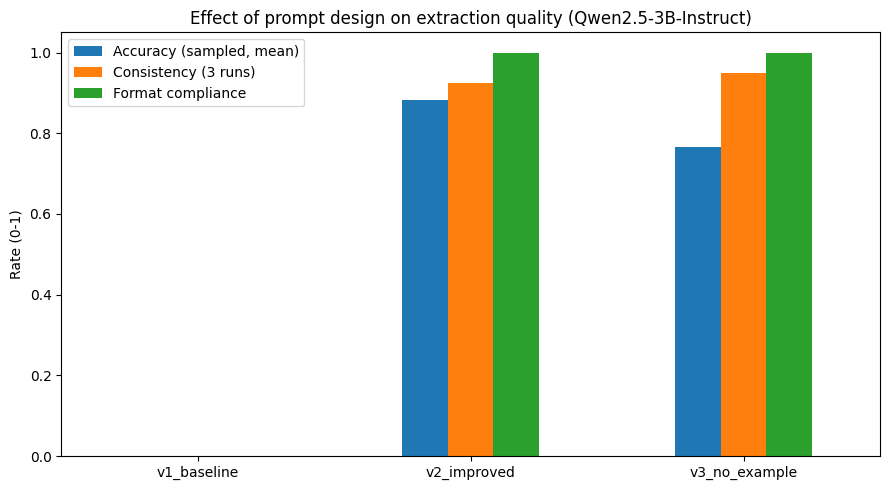

In [5]:
summary = summary_table(results)
print("Summary (rates from 0 to 1)")
display(summary.round(2))
print("Lab rubric scores (1-5)")
display(rubric_scores(summary))
print("Per-field accuracy (sampled runs)")
display(per_field_accuracy(results))

ax = summary[["Accuracy (sampled, mean)", "Consistency (3 runs)", "Format compliance"]].plot(
    kind="bar", figsize=(9, 5), rot=0, ylim=(0, 1.05))
ax.set_ylabel("Rate (0-1)")
ax.set_xlabel("")
ax.set_title("Effect of prompt design on extraction quality (Qwen2.5-3B-Instruct)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("outputs/week2_prompt_comparison.png", dpi=120)
plt.show()

### 7.1 Per-listing accuracy
Mean accuracy across the three sampled runs for each listing, which shows where each prompt fails.

In [6]:
by_listing = (results[results["run"] != "greedy"]
              .pivot_table(index="listing_id", columns="prompt", values="accuracy", aggfunc="mean")
              [list(PROMPTS)].round(2))
by_listing.index = [f"{i}. {t['key']['product_name']}" for i, t in zip(by_listing.index, TEST_SET)]
display(by_listing)

prompt,v1_baseline,v2_improved,v3_no_example
1. TerraFlask,0.0,0.60,0.60
2. GreenWave Tote,0.0,1.00,0.80
3. Solace Organic Cotton T-Shirt,0.0,0.73,0.60
4. UrbanBrew Coffee Grinder,0.0,0.80,0.60
5. EverLeaf Notebook,0.0,1.00,1.00
6. AquaPure Shampoo Bar,0.0,1.00,0.93
7. Nordic Trail Jacket,0.0,0.93,0.80
8. SunCharge Power Bank,0.0,1.00,0.80


### 7.2 Example outputs
Greedy outputs for the two trap listings (6 and 7), shown side by side for each prompt.

In [7]:
for lid in [6, 7]:
    print("#" * 90)
    print(TEST_SET[lid - 1]["listing"])
    print("Expected:", json.dumps(TEST_SET[lid - 1]["key"]))
    for p_name in PROMPTS:
        row = results[(results.prompt == p_name) & (results.listing_id == lid) & (results.run == "greedy")].iloc[0]
        print(f"\n--- {p_name} | accuracy {row.accuracy:.1f} | hallucinations {row.hallucinations} ---")
        print(row.raw_output[:900])
    print()

##########################################################################################
Product: AquaPure Shampoo Bar
Description: Zero waste and kind to the planet, with 100% natural ingredients. Wrapped in compostable paper certified to EN 13432.
Expected: {"product_name": "AquaPure Shampoo Bar", "recycled_content_percent": null, "certifications": ["EN 13432"], "has_vague_claim": true, "overall_rating": "PARTLY_SUBSTANTIATED"}

--- v1_baseline | accuracy 0.0 | hallucinations nan ---
Key information from the product description:
- Product Name: AquaPure Shampoo Bar
- Key Features: Zero waste, environmentally friendly, made with 100% natural ingredients
- Packaging: Wrapped in compostable paper certified to EN 13432

--- v2_improved | accuracy 1.0 | hallucinations 0.0 ---
{"product_name": "AquaPure Shampoo Bar", "recycled_content_percent": null, "certifications": ["EN 13432"], "vague_claims": ["Zero waste", "kind to the planet"], "has_vague_claim": true, "overall_rating": "PARTLY_SU

### 7.3 Error analysis
Every sampled output from the engineered prompts that got at least one field wrong, with the predicted values for the wrong fields.

In [8]:
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)

fail_rows = []
sampled = results[results["run"] != "greedy"]
for p_name in ["v2_improved", "v3_no_example"]:
    for _, r in sampled[sampled.prompt == p_name].iterrows():
        wrong = [f for f in SCORED_FIELDS if r[f"ok_{f}"] == 0]
        if wrong:
            obj = r["parsed"] or {}
            fail_rows.append({
                "prompt": p_name, "listing": r.listing_id, "run": r.run,
                "wrong_fields": ", ".join(wrong),
                "predicted": {f: obj.get(f) for f in wrong},
                "vague_claims_returned": obj.get("vague_claims"),
            })

errors = pd.DataFrame(fail_rows)
print("Error count by prompt and field:")
print(errors.assign(field=errors.wrong_fields.str.split(", ")).explode("field")
      .groupby(["prompt", "field"]).size().unstack(fill_value=0).to_string())
print()
print(errors.to_string(index=False))


Error count by prompt and field:
field          certifications  has_vague_claim  overall_rating  recycled_content_percent
prompt                                                                                  
v2_improved                 0                8               5                         1
v3_no_example               1                9              15                         3

       prompt  listing   run                    wrong_fields                                                           predicted                                                                  vague_claims_returned
  v2_improved        1 seed1 has_vague_claim, overall_rating {'has_vague_claim': True, 'overall_rating': 'PARTLY_SUBSTANTIATED'} [keeps drinks cold for 24 hours, replaces up to 150 single-use plastic bottles a year]
  v2_improved        1 seed2 has_vague_claim, overall_rating {'has_vague_claim': True, 'overall_rating': 'PARTLY_SUBSTANTIATED'} [keeps drinks cold for 24 hours, replaces up to 1

## 8. Analysis

### 8.1 Baseline versus engineered prompts
The baseline prompt (v1) produced **no usable output**: 0% valid JSON, so every field scored 0 and consistency could not be measured. This does not mean the model misread the listings. Read by a human, the v1 outputs were mostly faithful bullet-point summaries. The jacket output, for example, correctly listed both the 60% and 30% recycled figures. But each run chose its own headings, its own fields and its own wording. In one run "kind to the planet" became "environmentally friendly", which is a different claim. None of it could feed a screening system, and none of it gave a substantiation rating, because v1 never asked for one.

The engineered prompt (v2) changed this completely:

| Metric | v1 baseline | v2 improved | Change |
|---|---|---|---|
| Valid JSON / format compliance | 0% / 0% | 100% / 100% | +100 points |
| Accuracy (5 fields, sampled runs) | 0.00 | 0.88 | +0.88 |
| Consistency across 3 runs | 0.00 | 0.92 | +0.92 |
| Lab rubric (accuracy / consistency / format) | 1.0 / 1.0 / 1.0 | 4.5 / 4.7 / 5.0 | |
| Mean time per output | 2.55 s | 3.00 s | +0.45 s |

The longer prompt cost less than half a second per listing.

### 8.2 Which techniques mattered (ablation)
Comparing v2 with v3, which is identical except for the worked example, separates the contribution of each group of techniques.

- **Explicit schema, JSON-only instruction and type rules** produced the largest single gain: from 0% to 100% valid, compliant JSON. Both v2 and v3 achieved this, so the example was not needed for format.
- **The one-shot example** raised accuracy from 0.77 to 0.88. Almost all of that gain came from the classification step: `overall_rating` accuracy rose from **0.38 to 0.79**. Without the example, the model knew the four labels and their definitions but did not apply them. It labelled the Tote and the Power Bank, which contain only vague claims, as PARTLY_SUBSTANTIATED in all six of their v3 runs. Seeing one listing mapped to one rating taught the rule better than the written definition did.
- **The example also halved hallucinated values**, from 6 (v3) to 2 (v2).
- **Fields that copy text from the listing** (product name, certifications) were near-perfect with both prompts. Fields that require judgement (`has_vague_claim`, `overall_rating`) caused every remaining error. Prompt engineering fixes *format* far more reliably than it fixes *judgement*.

### 8.3 Remaining failures in the best prompt (v2)
The error analysis in Section 7.3 shows 14 wrong fields across 24 sampled v2 outputs, falling into four patterns.

1. **Measurable claims treated as vague (TerraFlask, 3/3 runs).** The model quoted "keeps drinks cold for 24 hours" and "replaces up to 150 single-use plastic bottles a year" as vague claims, although both contain numbers. This partly reflects an ambiguity in the prompt: "specific or measurable" was never defined precisely, and a strict reviewer could argue that "up to 150 bottles" still needs evidence. The answer key treats quantified claims as specific. The model was more cautious than the key.
2. **Vague claims missed beside a certification (Solace T-Shirt, 2/3 runs).** "Low-impact dyes" and "our most sustainable tee yet" were not flagged, and the listing was rated SUBSTANTIATED. The GOTS certification appears to have lent credibility to the rest of the listing, a halo effect that is exactly what greenwashing relies on.
3. **Ordinary product information read as an environmental claim (UrbanBrew Grinder, 3/3 runs).** "Ships in a cardboard box" was flagged as vague. Without the example, v3 went further and flagged "2-year warranty". The model over-applies the task and finds claims where there are none.
4. **Invented arithmetic (Nordic Trail Jacket).** The listing states 60% and 30%. The prompt explicitly said "if several are stated, use the first", yet the model returned **90%**, the sum, in v2's greedy run, in one v2 sampled run and in all three v3 runs. This is the most serious failure: a confident, precise-looking number that appears nowhere in the source.

Two further hallucinations appeared only without the example. In one v3 run the model returned "GOTS" for the shampoo listing, copying the certification named as an *illustration* in the field instructions. In another it paraphrased "save the planet" as "saving the planet" despite being told to copy phrases word for word.

### 8.4 Consistency is not accuracy
v3 was slightly *more* consistent than v2 (0.95 vs 0.92) while being clearly *less* accurate (0.77 vs 0.88). Its errors repeat on every run: the Tote, Power Bank and T-shirt were mislabelled identically three times. This illustrates the lab's warning that a model can be consistently wrong. Consistency only shows that a prompt is well specified, not that it is correct.

### 8.5 Limitations of this evaluation
- **Small test set.** With 8 listings, one listing equals 12.5% of the score, so differences of a few points are not significant.
- **Single annotator.** The answer key was written by one person, and the TerraFlask case shows that the definition of "measurable" is open to interpretation. A second annotator and an agreement score would strengthen the key.
- **What the hallucination check misses.** It counts values that do not appear in the source. It does not catch real text given the wrong meaning, such as "ships in a cardboard box" flagged as a vague claim.
- **Strict scoring of unstructured outputs.** v1 scores 0 by construction because unparseable output is treated as unusable. That fits an automated pipeline, but it understates how much a human could still learn from v1's prose.

## 9. Conclusions
Prompt design changed this model from unusable to largely reliable on a structured task, without changing the model or its settings. The improved prompt achieved 100% format compliance, 0.88 field accuracy and 0.92 consistency, against zero on all three for the baseline.

The techniques that contributed most were:
1. **An explicit output schema with types and a JSON-only instruction**, which alone made the output machine-readable.
2. **A worked example**, which doubled classification accuracy (0.38 to 0.79) and halved hallucinated values. Of all the individual changes tested, it gave the largest accuracy gain.
3. **Grounding and fallback rules** ("do not infer", null for missing values), which kept the model from inventing certifications or percentages on listings that had none.

The remaining errors all come from judgement rather than extraction: deciding what counts as vague, ignoring non-environmental text, and choosing one number from two. Three further changes are expected to help, in order of impact:
- **Move rule-based decisions into code.** `overall_rating` follows mechanically from the lists of vague and specific claims, so it can be computed deterministically. Likewise, a validator can reject any number that does not appear in the listing. Both remove whole classes of error instead of asking the model to follow the rule.
- **Sharpen the definitions with contrasting examples:** one quantified performance claim marked as specific, one listing with no environmental claims, and one certification sitting beside vague language.
- **Return all percentages as a list** instead of asking the model to choose one, which avoids the arithmetic failure seen on the jacket listing.

For deployment, outputs should be generated at temperature 0 and reviewed by a person whenever the model flags a vague claim or a PARTLY_SUBSTANTIATED rating. Those are the cases where it is least reliable, and where a wrong label carries reputational or regulatory risk for the seller. These findings feed directly into the claim-checking step of the capstone application.